In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models, layers, optimizers, datasets, backend
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import classification_report

In [2]:
(x_train, y_train), (x_test, y_test) = datasets.mnist.load_data()
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


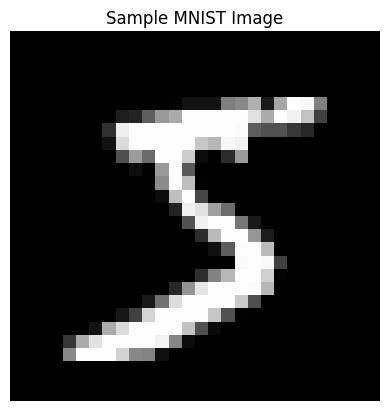

Label: 5


In [3]:
plt.imshow(x_train[0], cmap='gray')
plt.title("Sample MNIST Image")
plt.axis('off')
plt.show()
print("Label:", y_train[0])


In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


In [5]:
x_train = x_train.reshape(x_train.shape[0], 784)
x_test = x_test.reshape(x_test.shape[0], 784)
print("Training shape after flattening:", x_train.shape)
print("Testing shape after flattening:", x_test.shape)


Training shape after flattening: (60000, 784)
Testing shape after flattening: (10000, 784)


In [6]:
lb = LabelBinarizer()
y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)
print("Label shape:", y_train.shape)

Label shape: (60000, 10)


In [7]:
model = models.Sequential([
layers.Input(shape=(784,)),
layers.Dense(128, activation='sigmoid'),
layers.Dense(64, activation='sigmoid'),
layers.Dense(10, activation='softmax')
])

In [8]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
optimizer = optimizers.SGD(learning_rate=0.01)
model.compile(
optimizer=optimizer,
loss='categorical_crossentropy',
metrics=['accuracy']
)

In [10]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
x_train,
y_train,
epochs=10,
batch_size=128,
validation_split=0.1
)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.1619 - loss: 2.2833 - val_accuracy: 0.2272 - val_loss: 2.2547
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3288 - loss: 2.2301 - val_accuracy: 0.4460 - val_loss: 2.1984
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4604 - loss: 2.1689 - val_accuracy: 0.5305 - val_loss: 2.1257
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5294 - loss: 2.0861 - val_accuracy: 0.5862 - val_loss: 2.0259
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5631 - loss: 1.9725 - val_accuracy: 0.5965 - val_loss: 1.8900
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5897 - loss: 1.8255 - val_accuracy: 0.6177 - val_loss: 1.7238
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6153 - loss: 1.6571 - val_accuracy: 0.6592 - val_loss: 1.5448
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6521 - loss: 1.4887 - val_accuracy: 0.

In [12]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7317 - loss: 1.1342
Test Loss: 1.1341962814331055
Test Accuracy: 0.7317000031471252


In [13]:
predictions = model.predict(x_test)
predicted_classes = np.argmax(predictions, axis=1)
actual_classes = np.argmax(y_test, axis=1)
print("Predicted:", predicted_classes[:10])
print("Actual: ", actual_classes[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Predicted: [7 2 1 0 4 1 9 4 6 7]
Actual:  [7 2 1 0 4 1 4 9 5 9]


In [14]:
print(classification_report(
actual_classes,
predicted_classes
))

              precision    recall  f1-score   support

           0       0.81      0.97      0.88       980
           1       0.73      0.99      0.84      1135
           2       0.84      0.66      0.74      1032
           3       0.58      0.84      0.69      1010
           4       0.70      0.76      0.73       982
           5       0.84      0.32      0.46       892
           6       0.81      0.88      0.85       958
           7       0.70      0.88      0.78      1028
           8       0.76      0.40      0.52       974
           9       0.70      0.53      0.60      1009

    accuracy                           0.73     10000
   macro avg       0.75      0.72      0.71     10000
weighted avg       0.75      0.73      0.71     10000



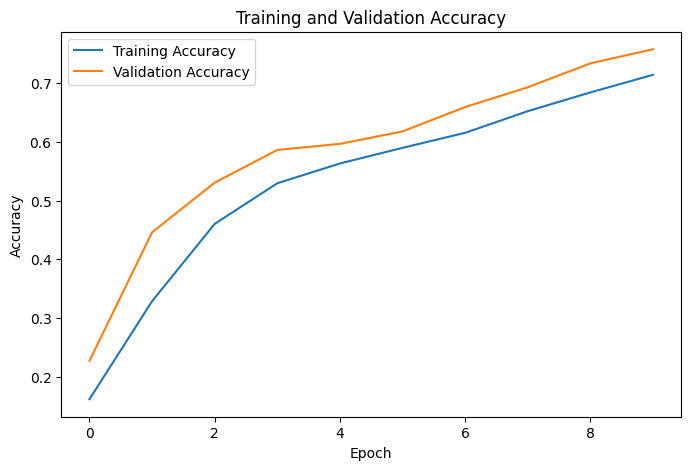

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

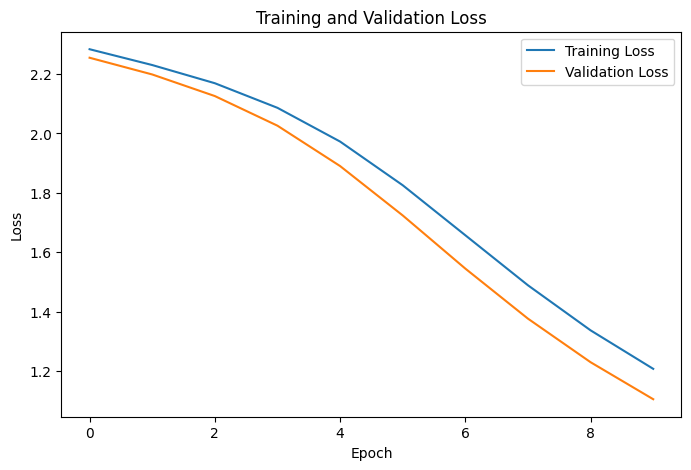

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


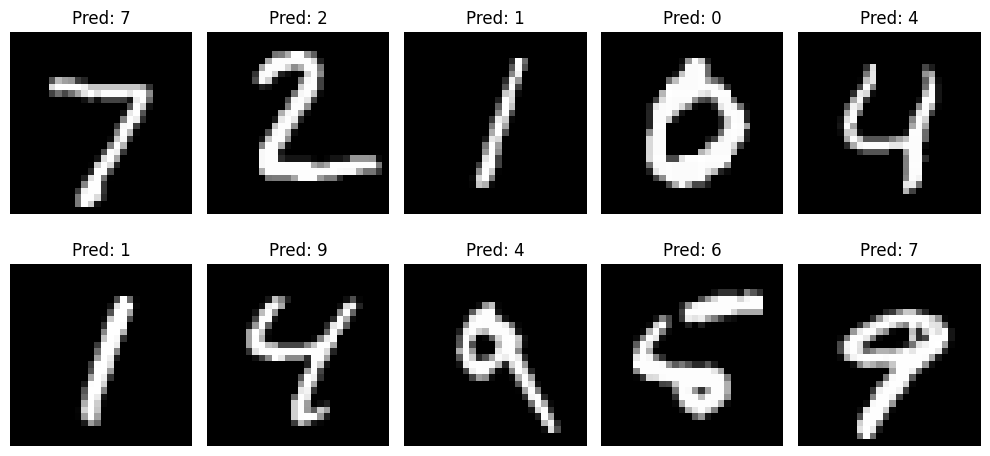

In [21]:
plt.figure(figsize=(10, 5))
for i in range(10):
  plt.subplot(2, 5, i + 1)
  image = x_test[i].reshape(28, 28)
  plt.imshow(image, cmap='gray')
  plt.title(f"Pred: {predicted_classes[i]}")
  plt.axis('off')
plt.tight_layout()
plt.show()
